# Introduction

This tutorial will take us through the steps to simulate stellar light curves using SAJAX for a variety of configurations.

> **Note:** This notebook needs the `examples` dependency group (Python 3.11–3.13). From the repository root, run `./setup_env.sh --examples` and select the `.venv` environment as the Jupyter kernel.

In [1]:
# Running this notebook on Google Colab? Colab doesn't have this repository
# checked out, so sajax and its example dependencies aren't installed --
# run this cell first. (Not needed locally, on Binder, or in the built
# docs -- sajax is already installed there.)
import sys

if "google.colab" in sys.modules:
    import urllib.request

    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/SamMerc/sajax/main/binder/requirements.txt",
        "requirements.txt",
    )
    # -e . installs from a local checkout, which Colab doesn't have --
    # install the package itself from GitHub instead, then everything
    # else from the same requirements Binder uses (single source of
    # truth, see docs/conf.py and binder/requirements.txt).
    with open("requirements.txt") as f:
        lines = [line for line in f if not line.startswith("-e .")]
    with open("requirements.txt", "w") as f:
        f.writelines(lines)

    import subprocess
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "-q",
        "sajax @ git+https://github.com/SamMerc/sajax.git@main",
        "-r", "requirements.txt",
    ])

## Imports and Setup

In [2]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sajax import quick_lc
from sajax.core import _compute_ar_shape
from speclib import Spectrum
# silencing exotic-ld warning
warnings.filterwarnings("ignore", message="pkg_resources is deprecated", category=UserWarning)
from exotic_ld import StellarLimbDarkening
import jax.numpy as jnp
import astropy.units as u
import os
import tempfile
from matplotlib.animation import FuncAnimation, PillowWriter
from IPython.display import Image, display

# Set random seed for reproducibility
np.random.seed(42)

## Load/generate some data
We extract some spectra for the quiet photosphere and active region from [`speclib`](https://speclib.readthedocs.io/en/latest/) and some quadratic limb-darkening coefficients that vary with wavelength from [`ExoTic-LD`](https://exotic-ld.readthedocs.io/en/latest/).

In [3]:
# Load spectra
# Provide some effective temperature, logg, and metallicity values for the quiet photosphere and active region
# Additionally, we decide on a grid of stellar spectra to use (in this case, we use PHOENIX)
T_quiet, logg_quiet, metal_quiet    = 3700, 4.5, 0.2   # quiet photosphere
T_active, logg_active, metal_active = 3000, 4.5, 0.2   # active region
model        = 'phoenix'                               #Stellar model grid

# The PHOENIX data downloaded from speclib can either be downloaded or reloaded from the .gz file stored in the repo
import gzip, shutil
from pathlib import Path
from speclib import utils as speclib_utils

_bundled_dir = Path("speclib_data") / "phoenix"
_cache_dir = speclib_utils.get_library_root() / "phoenix"
_cache_dir.mkdir(parents=True, exist_ok=True)
for _gz_path in sorted(_bundled_dir.glob("*.fits.gz")):
    _dest_path = _cache_dir / _gz_path.stem  # strip ".gz"
    if not _dest_path.exists():
        with gzip.open(_gz_path, "rb") as _src, open(_dest_path, "wb") as _dst:
            shutil.copyfileobj(_src, _dst)

#Wavelength range boundaries
wave_bounds     = [6_000, 25_000]                        # Angstrom
wavelengths = jnp.linspace(wave_bounds[0], wave_bounds[1], 100)*u.AA

#Instrument mode
mode = 'JWST_NIRSpec_Prism'

spec_obj_quiet = Spectrum.from_grid(feh=metal_quiet, teff=T_quiet, logg=logg_quiet, model_grid=model, wavelength=wavelengths)
spec_obj_active = Spectrum.from_grid(feh=metal_active, teff=T_active, logg=logg_active, model_grid=model, wavelength=wavelengths)
wavelength = spec_obj_quiet.wavelength.value
spec_quiet = spec_obj_quiet.flux.value
spec_active = spec_obj_active.flux.value
spec_contrast = spec_active / spec_quiet

# Retrieve the limb-darkening coefficients from exotic-ld
# Similarly to speclib, the exotic-ld data is either downloaded directly or reloaded from the .gz file stored in the repo
_bundled_ld_dir = Path("exotic_ld_data_bundled")
_ld_data_dir = Path("exotic_ld_data")
for _gz_path in sorted(_bundled_ld_dir.rglob("*.gz")):
    _rel_path = _gz_path.relative_to(_bundled_ld_dir).with_suffix("")  # strip ".gz"
    _dest_path = _ld_data_dir / _rel_path
    if not _dest_path.exists():
        _dest_path.parent.mkdir(parents=True, exist_ok=True)
        with gzip.open(_gz_path, "rb") as _src, open(_dest_path, "wb") as _dst:
            shutil.copyfileobj(_src, _dst)

sld_quiet = StellarLimbDarkening(metal_quiet, T_quiet, logg_quiet, model)
u1_wavelength = []
u2_wavelength = []
for wave_bin in jnp.stack([wavelength[:-1], wavelength[1:]], axis=1):
    u1, u2 = sld_quiet.compute_quadratic_ld_coeffs(wave_bin, mode)
    u1_wavelength.append(u1)
    u2_wavelength.append(u2)
#Convert to arrays and add a value at the end to get the same length as wavelengths
u1_wavelength = jnp.array(u1_wavelength + [u1_wavelength[-1]])
u2_wavelength = jnp.array(u2_wavelength + [u2_wavelength[-1]])

## Visualize Data, Input Spectra, and LD Coefficients

A quick sanity check on what we just loaded: a summary of the wavelength/flux/limb-darkening ranges, then a plot of the quiet and active-region spectra, their contrast ratio, and the wavelength-dependent quadratic limb-darkening coefficients ($u_1$, $u_2$).

In [4]:
# Print some data properties
print("=" * 60)
print("DATA SUMMARY")
print("=" * 60)
print(f"Wavelength range:     {wavelength.min():.0f} - {wavelength.max():.0f} Angstrom")
print(f"N wavelengths:        {len(wavelength)}")
print(rf"Flux quiet range:     {spec_quiet.min():.0f} - {spec_quiet.max():.0f}  [erg/(Angstrom s cm^2)]")
print(rf"Flux active range:    {spec_active.min():.0f} - {spec_active.max():.0f}  [erg/(Angstrom s cm^2)]")
print(rf"Contrast range:       {spec_contrast.min():.2f} - {spec_contrast.max():.2f}")
print(f"LD u1 range:          {u1_wavelength.min():.2f} - {u1_wavelength.max():.2f}")
print(f"LD u2 range:          {u2_wavelength.min():.2f} - {u2_wavelength.max():.2f}")
print("=" * 60)

DATA SUMMARY
Wavelength range:     6000 - 25000 Angstrom
N wavelengths:        100
Flux quiet range:     94113 - 863430  [erg/(Angstrom s cm^2)]
Flux active range:    51225 - 373218  [erg/(Angstrom s cm^2)]
Contrast range:       0.11 - 0.58
LD u1 range:          0.07 - 0.50
LD u2 range:          0.17 - 0.35


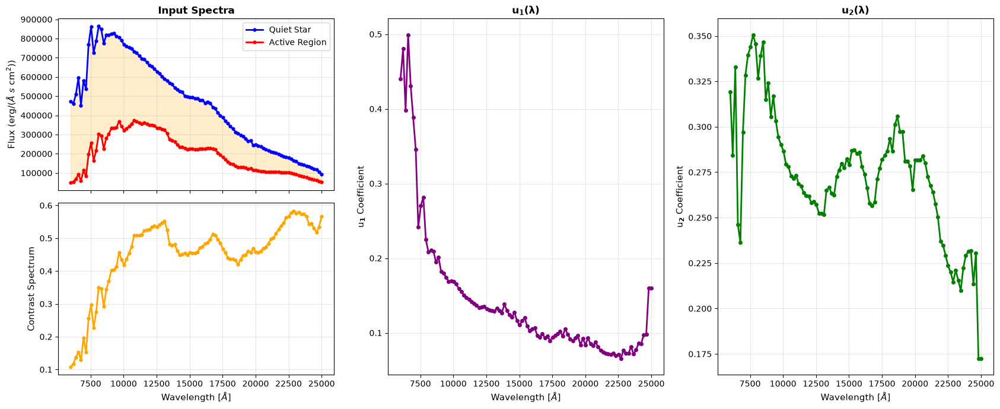

In [5]:
fig, axes = plt.subplot_mosaic(
    [['A', 'C', 'D'],
     ['B', 'C', 'D']],
    sharex=True, figsize=(17, 7))

# Plot 1: Spectra
ax1 = axes['A']
ax1.plot(wavelength, spec_quiet, 'b.', linestyle='solid', markersize=7, linewidth=2, label='Quiet Star')
ax1.plot(wavelength, spec_active, 'r.', linestyle='solid', markersize=7, linewidth=2, label='Active Region')
ax1.fill_between(wavelength, spec_quiet, spec_active, alpha=0.2, color='orange')
ax1.set_ylabel('Flux (erg$/(\AA \ s \ \mathrm{cm}^{2}$))', fontsize=11)
ax1.set_title('Input Spectra', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Plot 2: Contrast
ax2 = axes['B']
ax2.plot(wavelength, spec_contrast, '.', color='orange', linestyle='solid', markersize=7, linewidth=2)
ax2.set_xlabel('Wavelength [$\AA$]', fontsize=11)
ax2.set_ylabel('Contrast Spectrum', fontsize=11)
ax2.grid(True, alpha=0.3)

# Plot 2: LD u1 coefficient
ax3 = axes['C']
ax3.plot(wavelength, u1_wavelength, 'o-', linewidth=2, color='purple', markersize=4)
ax3.set_xlabel('Wavelength [$\AA$]', fontsize=11)
ax3.set_ylabel('u$_\mathbf{1}$ Coefficient', fontsize=11)
ax3.set_title('u$_\mathbf{1}$($\mathbf{\lambda}$)', fontsize=12, fontweight='bold')
ax3.grid(True, alpha=0.3)

# Plot 3: LD u2 coefficient
ax4 = axes['D']
ax4.plot(wavelength, u2_wavelength, 'o-', linewidth=2, color='green', markersize=4)
ax4.set_xlabel('Wavelength [$\AA$]', fontsize=11)
ax4.set_ylabel('u$_\mathbf{2}$ Coefficient', fontsize=11)
ax4.set_title('u$_\mathbf{2}$($\mathbf{\lambda}$)', fontsize=12, fontweight='bold')
ax4.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Case 1 - Single Spot, Basic Configuration 

This case shows a basic configuration: a rotating stellar surface with a single spot. We consider a single wavelength in this example, i.e. achromatic.

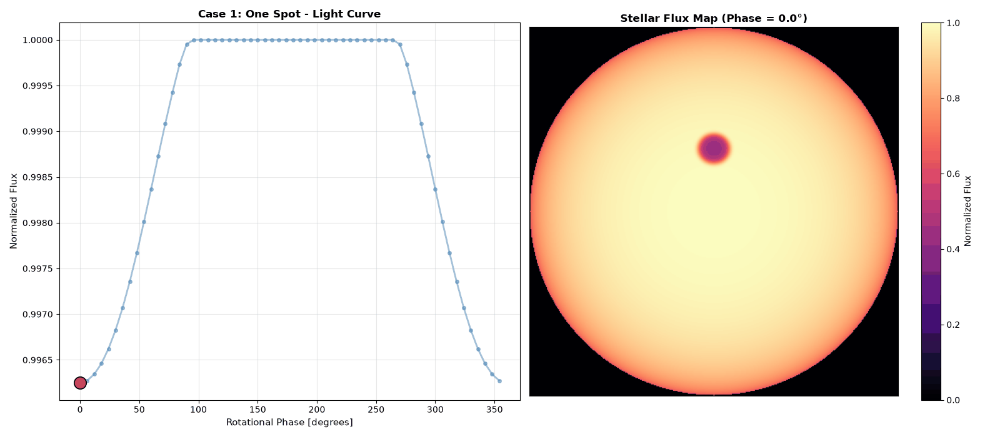

In [6]:
# Find a wavelength to use
wave_to_use = 15_000 #Angstrom
idx_to_use = jnp.abs(wave_to_use - wavelength).argmin()
u1 = u1_wavelength[idx_to_use]
u2 = u2_wavelength[idx_to_use]
flux_quiet = spec_quiet[idx_to_use]
flux_active = spec_active[idx_to_use]

# We define an array of time values from rotation phases we want to parse
P_ROT  = 5.0                                     # stellar rotation period [days]
phases = jnp.linspace(0, 360, 60, endpoint=False)
times  = phases / 360.0 * P_ROT

result_case1 = quick_lc(
    wavelength          = wave_to_use,
    flux_quiet          = flux_quiet,
    flux_active         = flux_active,
    ld_coeffs           = [u1, u2],                # quadratic law: [u1, u2]
    inc_star            = 90.0,                    # Equator-on view
    ar_lat              = 20.0,                    # Single spot at 20 degree lat
    ar_long             = 0.0,                     # Single spot at 0 degree long
    ar_size             = 5.0,                     # 5 degree radius
    ar_smoothness       = 3.0,                     # super-Gaussian order (see next section)
    times               = times,
    P_rot               = P_ROT,
    stellar_grid_size   = 200,                       # stellar radius in pixels
    ve                  = 2.0,                       # Equatorial velocity [km/s]
    ld_mode             = "quadratic",
)

# result[0] is (ntimes, nwave) -- wavelength-dependent, but with a
# single wavelength bin here, make_lc already squeezes that axis down to
# (ntimes,) for us.
lc           = jnp.asarray(result_case1[0])
lc          /= jnp.max(lc)  # Normalize to max flux   
lc_amplitude = jnp.max(lc) - jnp.min(lc)
star_maps    = result_case1[1]    
star_maps   /= jnp.max(star_maps)  # Normalize to max flux   
vmin, vmax   = float(jnp.min(star_maps)), float(jnp.max(star_maps))

# ------------------------------------------------------------------
# One combined figure/animation: light curve (with a marker tracking
# the current phase) alongside the rotating stellar flux map.
# ------------------------------------------------------------------
fig, (ax_lc, ax_map) = plt.subplots(1, 2, figsize=(16, 7))

ax_lc.plot(phases, lc, 'o-', linewidth=2, markersize=4,
           color='steelblue', alpha=0.5)
phase_marker, = ax_lc.plot([phases[0]], [lc[0]], 'o', markersize=14,
                           color='crimson', markeredgecolor='black',
                           markeredgewidth=1.2, zorder=5)
ax_lc.set_xlabel('Rotational Phase [degrees]', fontsize=11)
ax_lc.set_ylabel('Normalized Flux', fontsize=11)
ax_lc.set_title('Case 1: One Spot - Light Curve', fontsize=12, fontweight='bold')
ax_lc.grid(True, alpha=0.3)

im = ax_map.imshow(star_maps[0], cmap='magma', origin='lower', vmin=vmin, vmax=vmax)
map_title = ax_map.set_title(f'Stellar Flux Map (Phase = {phases[0]:.0f}°)',
                              fontsize=12, fontweight='bold')
ax_map.set_xticks([]); ax_map.set_yticks([])
plt.colorbar(im, ax=ax_map, label='Normalized Flux')
plt.tight_layout()

def _update(frame):
    phase_marker.set_data([phases[frame]], [lc[frame]])
    im.set_data(star_maps[frame])
    map_title.set_text(f'Stellar Flux Map (Phase = {phases[frame]:.1f}°)')
    return phase_marker, im, map_title

anim = FuncAnimation(fig, _update, frames=len(phases), interval=80, blit=False)

with tempfile.NamedTemporaryFile(suffix='.gif', delete=False) as _tmp:
    gif_path = _tmp.name
anim.save(gif_path, writer=PillowWriter(fps=9))
plt.close(fig)
with open(gif_path, 'rb') as f:
    gif_bytes = f.read()
os.remove(gif_path)

display(Image(data=gif_bytes, format='gif'))

## Case 2 - Multiple Active Regions

This case demonstrates `SAJAX`'s adaptability: multiple active regions with distinct contrast, smoothness, and limb-darkening coefficients placed on the stellar surface. Note that we've normalized with respect to the light curve's mean rather than the maximum value (as done in other cases) to highlight the presence of a facula, brighter than the quiet photosphere.

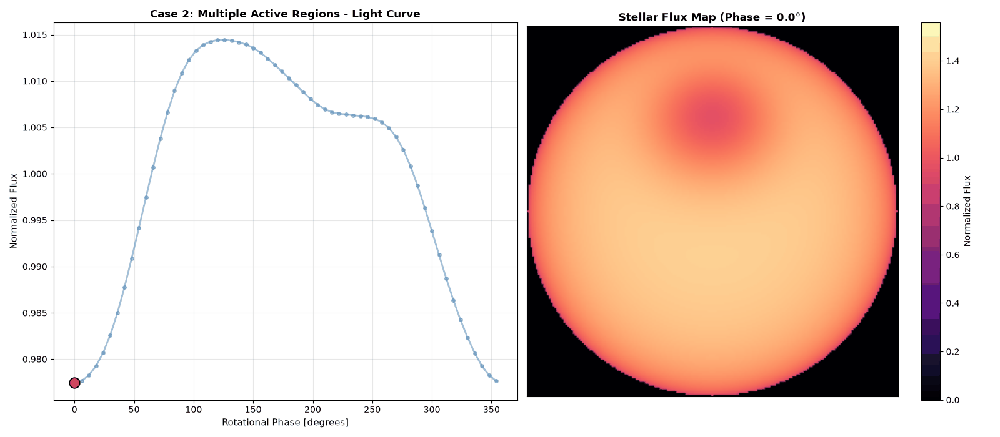

In [7]:
# Three active regions, each with their own contrast, location,
# limb-darkening coefficients,super-Gaussian smoothness order, and location
ar_lat_case2    = [30.0, -20.0, 5.0]
ar_long_case2   = [0.0, 120.0, 240.0]
ar_size_case2   = [20.0, 8.0, 13.0]
ar_smooth_case2 = [1.0, 5.0, 50.0]           # soft, moderate, ~hard-edged
scale_factors   = [0.70, 0.85, 1.10]         # cold, mild cold, hot active regions

flux_active_case2 = (jnp.array(scale_factors) * flux_quiet)[:, None]

ld_coeffs_active_case2 = jnp.array([
    [[u1 * 1.3, u2 * 0.7]],   # AR1: stronger limb darkening
    [[u1 * 0.9, u2 * 1.1]],   # AR2: weaker limb darkening
    [[u1 * 1.1, u2 * 0.9]],   # AR3: intermediate
])

result_case2 = quick_lc(
    wavelength          = wave_to_use,
    flux_quiet          = flux_quiet,
    flux_active         = flux_active_case2,
    ld_coeffs           = [u1, u2],                  
    inc_star            = 90.0,                      
    ar_lat              = ar_lat_case2,
    ar_long             = ar_long_case2,
    ar_size             = ar_size_case2,
    ar_smoothness       = ar_smooth_case2,
    ld_coeffs_active    = ld_coeffs_active_case2,
    times               = times,
    P_rot               = P_ROT,
    stellar_grid_size   = 100,
    ve                  = 2.0,
    ld_mode             = "quadratic",
)

# Single-wavelength call -- lc is already (ntimes,).
lc_case2        = jnp.asarray(result_case2[0]/jnp.mean(result_case2[0]))
star_maps_case2 = jnp.asarray(result_case2[1]/jnp.mean(result_case2[1]))
vmin2, vmax2    = float(star_maps_case2.min()), float(star_maps_case2.max())

fig, (ax_lc, ax_map) = plt.subplots(1, 2, figsize=(16, 7))

ax_lc.plot(phases, lc_case2, 'o-', linewidth=2, markersize=4,
           color='steelblue', alpha=0.5)
marker2, = ax_lc.plot([phases[0]], [lc_case2[0]], 'o', markersize=12, color='crimson',
                      markeredgecolor='black', markeredgewidth=1.2, zorder=5)
ax_lc.set_xlabel('Rotational Phase [degrees]', fontsize=11)
ax_lc.set_ylabel('Normalized Flux', fontsize=11)
ax_lc.set_title('Case 2: Multiple Active Regions - Light Curve', fontsize=12, fontweight='bold')
ax_lc.grid(True, alpha=0.3)

im2 = ax_map.imshow(star_maps_case2[0], cmap='magma', origin='lower', vmin=vmin2, vmax=vmax2)
map_title2 = ax_map.set_title(f'Stellar Flux Map (Phase = {phases[0]:.0f}°)',
                               fontsize=12, fontweight='bold')
ax_map.set_xticks([]); ax_map.set_yticks([])
plt.colorbar(im2, ax=ax_map, label='Normalized Flux')
plt.tight_layout()

def _update_case2(frame):
    marker2.set_data([phases[frame]], [lc_case2[frame]])
    im2.set_data(star_maps_case2[frame])
    map_title2.set_text(f'Stellar Flux Map (Phase = {phases[frame]:.1f}°)')
    return marker2, im2, map_title2

anim2 = FuncAnimation(fig, _update_case2, frames=len(phases), interval=80, blit=False)
with tempfile.NamedTemporaryFile(suffix='.gif', delete=False) as _tmp:
    gif_path = _tmp.name
anim2.save(gif_path, writer=PillowWriter(fps=9))
plt.close(fig)
with open(gif_path, 'rb') as f:
    gif_bytes = f.read()
os.remove(gif_path)
display(Image(data=gif_bytes, format='gif'))

## Case 3 - Single Active Region with Umbra and Penumbra

A relevant setup for stellar spots is for them to have two components: a dark central umbra and a lighter peripheral penumbra. Given `SAJAX`'s parametrization of active regions as super-Gaussians with smooth overlap, such a configuration is easy to generate.

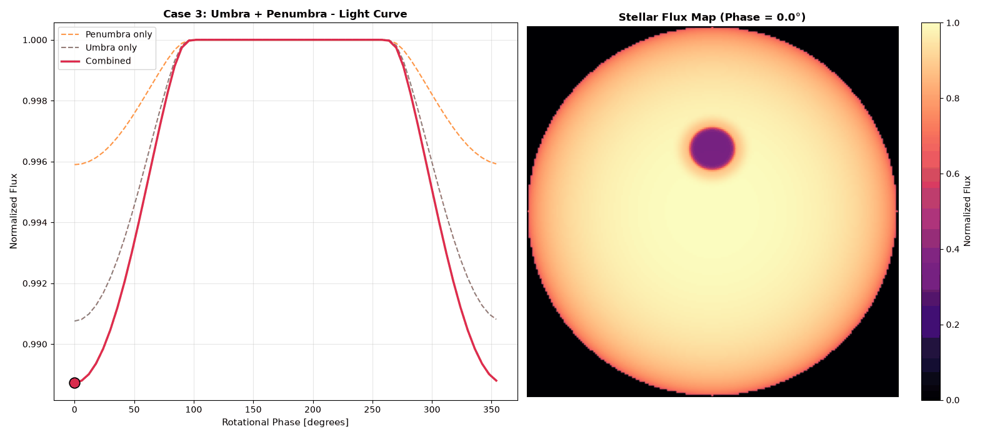

In [8]:
AR3_LAT, AR3_LONG = 20.0, 0.0
TINY = 0.0001   # effectively "no AR" (negligible angular size) - needed to remove one of the components

penumbra_flux = 0.85 * flux_quiet     # mild dimming
umbra_flux    = 0.35 * flux_quiet     # strong dimming

def _case3(pen_size, umb_size):
    return quick_lc(
        wavelength        = wave_to_use,
        flux_quiet        = flux_quiet,
        flux_active       = jnp.array([[penumbra_flux], [umbra_flux]]),
        ld_coeffs         = [u1, u2],                  
        inc_star          = 90.0,                      
        ar_lat            = [AR3_LAT, AR3_LAT],
        ar_long           = [AR3_LONG, AR3_LONG],
        ar_size           = [pen_size, umb_size],
        ar_smoothness     = [3.0, 8.0],     # soft penumbra edge, sharper umbra edge
        times             = times,
        P_rot             = P_ROT,
        stellar_grid_size = 100,
        ve                = 2.0,
        ld_mode           = "quadratic",
    )

result_penumbra_only = _case3(10.0, TINY)
result_umbra_only    = _case3(TINY, 7.0)
result_case3         = _case3(10.0, 7.0)

# Single-wavelength call -- lc is already (ntimes,).
lc_case3        = jnp.asarray(result_case3[0]/jnp.max(result_case3[0]))
lc_penumbra     = jnp.asarray(result_penumbra_only[0]/jnp.max(result_penumbra_only[0]))
lc_umbra        = jnp.asarray(result_umbra_only[0]/jnp.max(result_umbra_only[0]))
star_maps_case3 = jnp.asarray(result_case3[1]/jnp.max(result_case3[1]))
vmin3, vmax3    = float(star_maps_case3.min()), float(star_maps_case3.max())

fig, (ax_lc, ax_map) = plt.subplots(1, 2, figsize=(16, 7))

ax_lc.plot(phases, lc_penumbra, '--', linewidth=1.5, color='#ff7f0e', alpha=0.8, label='Penumbra only')
ax_lc.plot(phases, lc_umbra,    '--', linewidth=1.5, color='#8c564b', alpha=0.8, label='Umbra only')
ax_lc.plot(phases, lc_case3,    '-',  linewidth=2.5, color='crimson', alpha=0.9, label='Combined')
marker3, = ax_lc.plot([phases[0]], [lc_case3[0]], 'o', markersize=12, color='crimson',
                      markeredgecolor='black', markeredgewidth=1.2, zorder=5)
ax_lc.set_xlabel('Rotational Phase [degrees]', fontsize=11)
ax_lc.set_ylabel('Normalized Flux', fontsize=11)
ax_lc.set_title('Case 3: Umbra + Penumbra - Light Curve', fontsize=12, fontweight='bold')
ax_lc.legend(fontsize=10)
ax_lc.grid(True, alpha=0.3)

im3 = ax_map.imshow(star_maps_case3[0], cmap='magma', origin='lower', vmin=vmin3, vmax=vmax3)
map_title3 = ax_map.set_title(f'Stellar Flux Map (Phase = {phases[0]:.0f}°)',
                               fontsize=12, fontweight='bold')
ax_map.set_xticks([]); ax_map.set_yticks([])
plt.colorbar(im3, ax=ax_map, label='Normalized Flux')
plt.tight_layout()

def _update_case3(frame):
    marker3.set_data([phases[frame]], [lc_case3[frame]])
    im3.set_data(star_maps_case3[frame])
    map_title3.set_text(f'Stellar Flux Map (Phase = {phases[frame]:.1f}°)')
    return marker3, im3, map_title3

anim3 = FuncAnimation(fig, _update_case3, frames=len(phases), interval=80, blit=False)
with tempfile.NamedTemporaryFile(suffix='.gif', delete=False) as _tmp:
    gif_path = _tmp.name
anim3.save(gif_path, writer=PillowWriter(fps=9))
plt.close(fig)
with open(gif_path, 'rb') as f:
    gif_bytes = f.read()
os.remove(gif_path)
display(Image(data=gif_bytes, format='gif'))

## Case 4 - Wavelength Dependence of Spectra and Limb-Darkening
`SAJAX` internally `vmap`'s light curve computation over wavelength, allowing users to produce 2D light curve plots (as seen below) quickly.

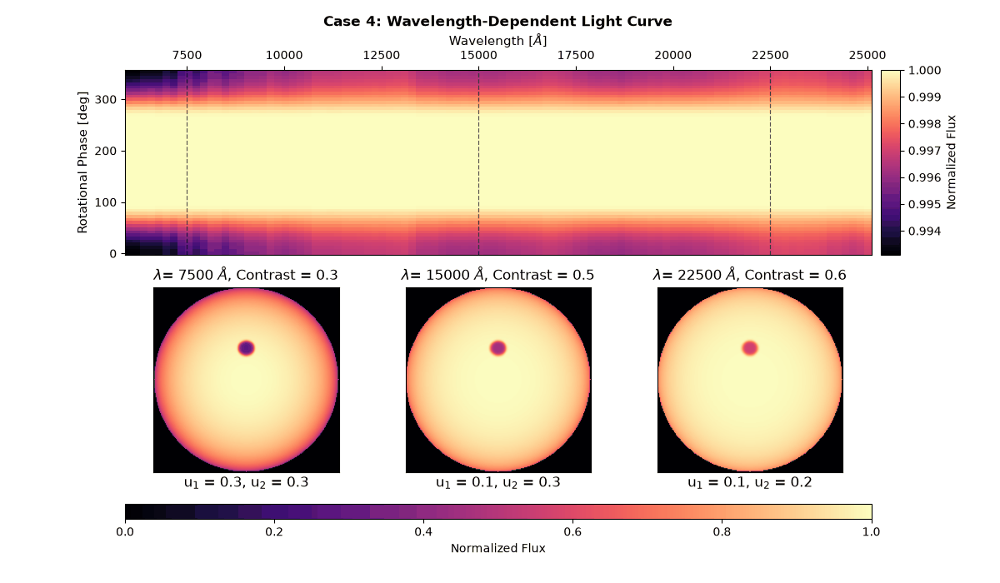

In [9]:
# Same single spot as Case 1 (lat=20, long=0, size=5, n=3), but now
# evaluated over the full wavelength grid

result_case4 = quick_lc(
    wavelength          = wavelength,
    flux_quiet          = spec_quiet,
    flux_active         = spec_active,
    ld_coeffs           = [u1_wavelength, u2_wavelength],              
    inc_star            = 90.0,                      
    ar_lat              = 20.0,
    ar_long             = 0.0,
    ar_size             = 5.0,
    ar_smoothness       = 3.0,
    times               = times,
    P_rot               = P_ROT,
    stellar_grid_size   = 100,
    ve                  = 2.0,
    ld_mode             = "quadratic",
)

# result[0] is (ntimes, nwave) -- normalised flux at every wavelength
# bin we passed in. Each wavelength's own light curve (a column of this
# array) is normalized to its own maximum.
flux_wl_map = jnp.asarray(result_case4[0] / jnp.max(result_case4[0], axis=0))

# -----------------------------------------------------
# Stellar flux maps at three representative wavelengths
# -----------------------------------------------------
plot_wavelengths = [7500.0, 15000.0, 22500.0]

maps_by_wl = []
for pw in plot_wavelengths:
    result_pw = quick_lc(
        wavelength          = wavelength,
        flux_quiet          = spec_quiet,
        flux_active         = spec_active,
        ld_coeffs           = [u1_wavelength, u2_wavelength],              
        inc_star            = 90.0,  
        ar_lat              = 20.0,
        ar_long             = 0.0,
        ar_size             = 5.0,
        ar_smoothness       = 3.0,
        times               = times,
        P_rot               = P_ROT,
        stellar_grid_size   = 100,
        ve                  = 2.0,
        ld_mode             = "quadratic",
        plot_map_wavelength = pw,
    )
    maps_by_wl.append(jnp.asarray(result_pw[1]/jnp.max(result_pw[1])))   # (ntimes, n, n)

fig, axes = plt.subplot_mosaic(
    [['A', 'A', 'A', 'col_bar1'],
     ['B', 'C', 'D', '.'],
     ['col_bar2', 'col_bar2', 'col_bar2', '.']],
    figsize=(12, 7), height_ratios=[1, 1, 0.08],
    width_ratios=[1, 1, 1, 0.08], 
    gridspec_kw={'hspace':0.25, 'wspace':0.05})

# ----------------------------------------------------------------------
# Top (spans all three columns): wavelength-resolved light curve heatmap
# ----------------------------------------------------------------------
lc_vmin = jnp.min(flux_wl_map)
lc_vmax = jnp.max(flux_wl_map)
im_top = axes['A'].pcolormesh(wavelength, phases, flux_wl_map, shading='auto', cmap='magma', vmin=lc_vmin, vmax=lc_vmax)
axes['A'].set_xlabel('Wavelength [$\AA$]', fontsize=11)
axes['A'].set_ylabel('Rotational Phase [deg]', fontsize=11)
axes['A'].set_title('Case 4: Wavelength-Dependent Light Curve', fontsize=12, fontweight='bold', y=1.2)
for pw in plot_wavelengths:
    axes['A'].axvline(pw, color='k', linestyle='--', linewidth=1, alpha=0.6)
sm = plt.cm.ScalarMappable(cmap='magma', norm=plt.Normalize(vmin=lc_vmin, vmax=lc_vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=axes['col_bar1'],label='Normalized Flux')
axes['A'].xaxis.set_label_position('top')
axes['A'].xaxis.set_ticks_position('top')

# ------------------------------------------------------------------
# Bottom: rotating stellar flux map at each of the three wavelengths
# ------------------------------------------------------------------
map_ims = []
vmin_map, vmax_map = jnp.min(jnp.array(maps_by_wl)), jnp.max(jnp.array(maps_by_wl))
for i, (pw, ax_name) in enumerate(zip(plot_wavelengths, ['B', 'C', 'D'])):
    maps_i = maps_by_wl[i]
    im = axes[ax_name].imshow(maps_i[0], cmap='magma', origin='lower', vmin=vmin_map, vmax=vmax_map)
    wave_idx = jnp.abs(pw - wavelength).argmin()
    title_str = '$\lambda$'+f'= {pw:.0f}'+' $\AA$'+f', Contrast = {spec_active[wave_idx]/spec_quiet[wave_idx]:.1f}'
    axes[ax_name].set_title(title_str, fontsize=12)
    axes[ax_name].set_xticks([]); axes[ax_name].set_yticks([])
    axes[ax_name].text(0.5, -0.1, f'u$_1$ = {u1_wavelength[wave_idx]:.1f}, u$_2$ = {u2_wavelength[wave_idx]:.1f}', 
                       fontsize=12, ha='center', va='bottom', transform=axes[ax_name].transAxes)
    map_ims.append(im)
sm = plt.cm.ScalarMappable(cmap='magma', norm=plt.Normalize(vmin=vmin_map, vmax=vmax_map))
sm.set_array([])
cbar = fig.colorbar(sm, cax=axes['col_bar2'], orientation='horizontal', label='Normalized Flux')

def _update_case4(frame):
    for im, maps_i in zip(map_ims, maps_by_wl):
        im.set_data(maps_i[frame])
    return map_ims

anim4 = FuncAnimation(fig, _update_case4, frames=len(phases), interval=80, blit=False)
with tempfile.NamedTemporaryFile(suffix='.gif', delete=False) as _tmp:
    gif_path = _tmp.name
anim4.save(gif_path, writer=PillowWriter(fps=9))
plt.close(fig)
with open(gif_path, 'rb') as f:
    gif_bytes = f.read()
os.remove(gif_path)
display(Image(data=gif_bytes, format='gif'))

## Case 5 - Planet Transit with Active-Region Crossing

This case demonstrates how to use `quick_lc`'s optional transit parameters (`t0`/`period`/`a_over_rstar`/`inclination`/`k`) to include a planetary transit across the stellar surface from Case 1.

We compare three scenarios:
  
1. **Transit only** — quiet star, no active regions.
  
2. **Stellar activity only** — spot visible, no transit.
  
3. **Combined** — planet and active region present; the starspot crossing event is clearly visible.

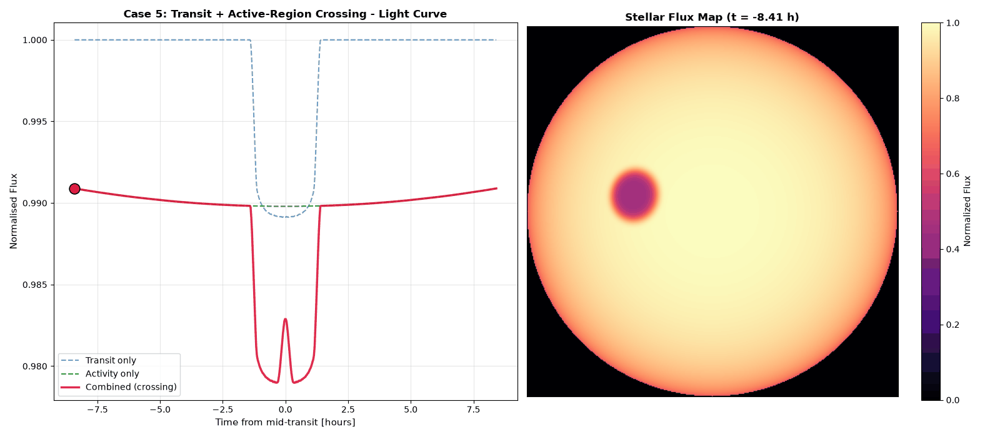

In [10]:
# ------------------------------------------------------------------
# Time array: +/-3x the approximate transit duration
# ------------------------------------------------------------------
RSTAR        = 1.0
P_ROT        = 5.0     
STELLAR_GRID = 200     # stellar radius in pixels

# Transit-geometry parameters are individual keyword arguments -- the same
# calling convention as the AR parameters (ar_lat, ar_size, ...) above.
T0           = 0.0
PERIOD       = 5.0
A_OVER_RSTAR = 15.0
INCLINATION  = jnp.pi / 2.0    # perfectly edge-on
K            = 0.1            # Rp/R* = 0.1
ECC          = 0.0
OMEGA_PERI   = 0.0

# Transit duration
# Impact parameter (eccentricity-corrected)
b = (
    (A_OVER_RSTAR * jnp.cos(INCLINATION)) / RSTAR
    * (1 - ECC**2) / (1 + ECC * jnp.sin(OMEGA_PERI))
)
# Argument inside arcsin
arg = (
    (1/A_OVER_RSTAR)
    * jnp.sqrt((1 + K)**2 - b**2)
    / jnp.sin(INCLINATION)
)
# Numerical safety
arg = np.clip(arg, -1.0, 1.0)
# Transit duration
T_dur = (
    (PERIOD / jnp.pi)
    * jnp.sqrt(1 - ECC**2) / (1 + ECC * jnp.sin(OMEGA_PERI))
    * jnp.arcsin(arg)
)
# Time array: +/-3x the transit duration
times = jnp.linspace(-3.0 * T_dur, 3.0 * T_dur, 600)

# ------------------------------------------------------------------
# Scenario 1: Transit only (no active region)
# ------------------------------------------------------------------
result_transit_only = quick_lc(
    wavelength        = wave_to_use,
    flux_quiet        = flux_quiet,
    flux_active       = flux_active,
    ld_coeffs         = [u1, u2],                  
    inc_star          = 90.0,  
    ar_lat            = 5.0,
    ar_long           = 0.0,
    ar_size           = 0.0001,   # negligible -- effectively no AR
    ar_smoothness     = 3.0,
    times             = times,
    P_rot             = P_ROT,
    t0                = T0,
    period            = PERIOD, 
    a_over_rstar      = A_OVER_RSTAR,
    inclination       = INCLINATION, 
    k                 = K, 
    ecc               = ECC, 
    omega_peri        = OMEGA_PERI,
    stellar_grid_size = STELLAR_GRID,
    ve                = 2.0,
    ld_mode           = "quadratic",
)

# ------------------------------------------------------------------
# Scenario 2: Stellar activity only (no transit, k -> 0)
# ------------------------------------------------------------------
result_activity_only = quick_lc(
    wavelength        = wave_to_use,
    flux_quiet        = flux_quiet,
    flux_active       = flux_active,
    ld_coeffs         = [u1, u2],                  
    inc_star          = 90.0,  
    ar_lat            = 5.0,
    ar_long           = 0.0,
    ar_size           = 8.0,
    ar_smoothness     = 3.0,
    times             = times,
    P_rot             = P_ROT,
    t0                = T0,
    period            = PERIOD, 
    a_over_rstar      = A_OVER_RSTAR,
    inclination       = INCLINATION, 
    k                 = 0.0, 
    ecc               = ECC, 
    omega_peri        = OMEGA_PERI,
    # k = 0.0 -- zero-radius planet -- no occultation
    stellar_grid_size = STELLAR_GRID,
    ve                = 2.0,
    ld_mode           = "quadratic",
)

# ------------------------------------------------------------------
# Scenario 3: Combined -- transit crosses the spot
# ------------------------------------------------------------------
result_transit_combined = quick_lc(
    wavelength        = wave_to_use,
    flux_quiet        = flux_quiet,
    flux_active       = flux_active,
    ld_coeffs         = [u1, u2],                  
    inc_star          = 90.0,  
    ar_lat            = 5.0,
    ar_long           = 0.0,
    ar_size           = 8.0,
    ar_smoothness     = 3.0,
    times             = times,
    P_rot             = P_ROT,
    t0                = T0,
    period            = PERIOD, 
    a_over_rstar      = A_OVER_RSTAR,
    inclination       = INCLINATION, 
    k                 = K, 
    ecc               = ECC, 
    omega_peri        = OMEGA_PERI,
    stellar_grid_size = STELLAR_GRID,
    ve                = 2.0,
    ld_mode           = "quadratic",
)

lc_transit   = jnp.asarray(result_transit_only[0]/jnp.max(result_transit_only[0]))
lc_activity  = jnp.asarray(result_activity_only[0]/jnp.max(result_transit_only[0]))
lc_combined5 = jnp.asarray(result_transit_combined[0]/jnp.max(result_transit_only[0]))

star_maps_combined5 = jnp.asarray(result_transit_combined[1]/jnp.max(result_transit_combined[1]))
vmin5, vmax5         = float(star_maps_combined5.min()), float(star_maps_combined5.max())

# Subsample the animation frames -- times has 600 points; this keeps the GIF a manageable size.
frame_idx = jnp.arange(0, len(times), 4)

# ------------------------------------------------------------------
# Plotting: left = light curve with all three scenarios (marker tracking
# the current time on the combined curve); right = rotating/transiting
# stellar flux map, same layout as Case 1.
# ------------------------------------------------------------------
fig, (ax_lc, ax_map) = plt.subplots(1, 2, figsize=(16, 7))

ax_lc.plot(times * 24, lc_transit,   '--', linewidth=1.5, color='steelblue', alpha=0.8, label='Transit only')
ax_lc.plot(times * 24, lc_activity,  '--', linewidth=1.5, color='green',     alpha=0.8, label='Activity only')
ax_lc.plot(times * 24, lc_combined5, '-',  linewidth=2.5, color='crimson',   alpha=0.9, label='Combined (crossing)')
marker5, = ax_lc.plot([times[0] * 24], [lc_combined5[0]], 'o', markersize=12, color='crimson',
                      markeredgecolor='black', markeredgewidth=1.2, zorder=5)
ax_lc.set_xlabel('Time from mid-transit [hours]', fontsize=11)
ax_lc.set_ylabel('Normalised Flux', fontsize=11)
ax_lc.set_title('Case 5: Transit + Active-Region Crossing - Light Curve', fontsize=12, fontweight='bold')
ax_lc.legend(fontsize=10)
ax_lc.grid(True, alpha=0.3)

im5 = ax_map.imshow(star_maps_combined5[frame_idx[0]], cmap='magma', origin='lower', vmin=vmin5, vmax=vmax5)
map_title5 = ax_map.set_title(f'Stellar Flux Map (t = {times[frame_idx[0]] * 24:+.2f} h)',
                               fontsize=12, fontweight='bold')
ax_map.set_xticks([]); ax_map.set_yticks([])
plt.colorbar(im5, ax=ax_map, label='Normalized Flux')
plt.tight_layout()

def _update_case5(i):
    frame = frame_idx[i]
    marker5.set_data([times[frame] * 24], [lc_combined5[frame]])
    im5.set_data(star_maps_combined5[frame])
    map_title5.set_text(f'Stellar Flux Map (t = {times[frame] * 24:+.2f} h)')
    return marker5, im5, map_title5

anim5 = FuncAnimation(fig, _update_case5, frames=len(frame_idx), interval=60, blit=False)
with tempfile.NamedTemporaryFile(suffix='.gif', delete=False) as _tmp:
    gif_path = _tmp.name
anim5.save(gif_path, writer=PillowWriter(fps=15))
plt.close(fig)
with open(gif_path, 'rb') as f:
    gif_bytes = f.read()
os.remove(gif_path)
display(Image(data=gif_bytes, format='gif'))

## Case 6 - Planet Transit (on a Tilted Orbit) with Active-Region Crossing

This case demonstrates `quick_lc`'s `sp_orb` parameter -- the sky-projected spin-orbit angle $\lambda$ between the planet's transit chord and the stellar equator. `sp_orb=0` (the default) reproduces the aligned transit from Case 5, where the chord runs parallel to the projected stellar equator. Increasing `sp_orb` rotates the chord about the stellar centre, without changing anything else about the transit (depth, duration) or the active region.

We reuse the exact same spot and transit geometry as Case 5, and only change `sp_orb`.

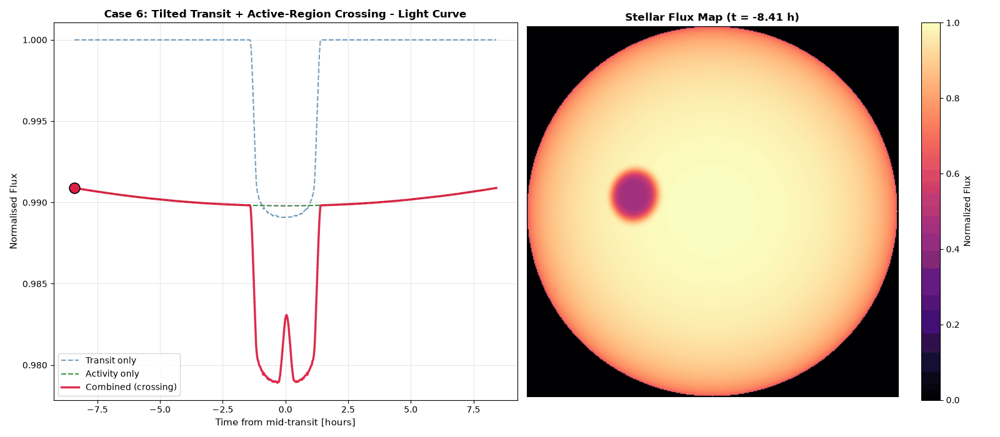

In [11]:
# ------------------------------------------------------------------
# Time array: +/-3x the approximate transit duration
# ------------------------------------------------------------------
RSTAR        = 1.0
P_ROT        = 5.0     
STELLAR_GRID = 200     # stellar radius in pixels

# Transit-geometry parameters are individual keyword arguments -- the same
# calling convention as the AR parameters (ar_lat, ar_size, ...) above.
T0           = 0.0
PERIOD       = 5.0
A_OVER_RSTAR = 15.0
INCLINATION  = jnp.pi / 2.0    # perfectly edge-on
K            = 0.1            # Rp/R* = 0.1
ECC          = 0.0
OMEGA_PERI   = 0.0
SP_ORB       = 20.0            # sp_orb is in degrees

# Transit duration
# Impact parameter (eccentricity-corrected)
b = (
    (A_OVER_RSTAR * jnp.cos(INCLINATION)) / RSTAR
    * (1 - ECC**2) / (1 + ECC * jnp.sin(OMEGA_PERI))
)
# Argument inside arcsin
arg = (
    (1/A_OVER_RSTAR)
    * jnp.sqrt((1 + K)**2 - b**2)
    / jnp.sin(INCLINATION)
)
# Numerical safety
arg = np.clip(arg, -1.0, 1.0)
# Transit duration
T_dur = (
    (PERIOD / jnp.pi)
    * jnp.sqrt(1 - ECC**2) / (1 + ECC * jnp.sin(OMEGA_PERI))
    * jnp.arcsin(arg)
)
# Time array: +/-3x the transit duration
times = jnp.linspace(-3.0 * T_dur, 3.0 * T_dur, 600)

# ------------------------------------------------------------------
# Scenario 1: Transit only (no active region)
# ------------------------------------------------------------------
result_transit_only = quick_lc(
    wavelength        = wave_to_use,
    flux_quiet        = flux_quiet,
    flux_active       = flux_active,
    ld_coeffs         = [u1, u2],                  
    inc_star          = 90.0,  
    ar_lat            = 5.0,
    ar_long           = 0.0,
    ar_size           = 0.0001,   # negligible -- effectively no AR
    ar_smoothness     = 3.0,
    times             = times,
    P_rot             = P_ROT,
    t0                = T0,
    period            = PERIOD, 
    a_over_rstar      = A_OVER_RSTAR,
    inclination       = INCLINATION, 
    k                 = K, 
    ecc               = ECC, 
    omega_peri        = OMEGA_PERI,
    sp_orb            = SP_ORB,
    stellar_grid_size = STELLAR_GRID,
    ve                = 2.0,
    ld_mode           = "quadratic",
)

# ------------------------------------------------------------------
# Scenario 2: Stellar activity only (no transit, k -> 0)
# ------------------------------------------------------------------
result_activity_only = quick_lc(
    wavelength        = wave_to_use,
    flux_quiet        = flux_quiet,
    flux_active       = flux_active,
    ld_coeffs         = [u1, u2],                  
    inc_star          = 90.0,  
    ar_lat            = 5.0,
    ar_long           = 0.0,
    ar_size           = 8.0,
    ar_smoothness     = 3.0,
    times             = times,
    P_rot             = P_ROT,
    t0                = T0,
    period            = PERIOD, 
    a_over_rstar      = A_OVER_RSTAR,
    inclination       = INCLINATION, 
    k                 = 0.0, 
    ecc               = ECC, 
    omega_peri        = OMEGA_PERI,
    sp_orb            = SP_ORB,
    # k = 0.0 -- zero-radius planet -- no occultation
    stellar_grid_size = STELLAR_GRID,
    ve                = 2.0,
    ld_mode           = "quadratic",
)

# ------------------------------------------------------------------
# Scenario 3: Combined -- transit crosses the spot
# ------------------------------------------------------------------
result_transit_combined = quick_lc(
    wavelength        = wave_to_use,
    flux_quiet        = flux_quiet,
    flux_active       = flux_active,
    ld_coeffs         = [u1, u2],                  
    inc_star          = 90.0,  
    ar_lat            = 5.0,
    ar_long           = 0.0,
    ar_size           = 8.0,
    ar_smoothness     = 3.0,
    times             = times,
    P_rot             = P_ROT,
    t0                = T0,
    period            = PERIOD, 
    a_over_rstar      = A_OVER_RSTAR,
    inclination       = INCLINATION, 
    k                 = K, 
    ecc               = ECC, 
    omega_peri        = OMEGA_PERI,
    sp_orb            = SP_ORB,
    stellar_grid_size = STELLAR_GRID,
    ve                = 2.0,
    ld_mode           = "quadratic",
)

lc_transit   = jnp.asarray(result_transit_only[0]/jnp.max(result_transit_only[0]))
lc_activity  = jnp.asarray(result_activity_only[0]/jnp.max(result_transit_only[0]))
lc_combined6 = jnp.asarray(result_transit_combined[0]/jnp.max(result_transit_only[0]))

star_maps_combined6 = jnp.asarray(result_transit_combined[1]/jnp.max(result_transit_combined[1]))
vmin6, vmax6         = float(star_maps_combined6.min()), float(star_maps_combined6.max())

# Subsample the animation frames -- times has 600 points; this keeps the GIF a manageable size.
frame_idx = jnp.arange(0, len(times), 4)

# ------------------------------------------------------------------
# Plotting: left = light curve with all three scenarios (marker tracking
# the current time on the combined curve); right = rotating/transiting
# stellar flux map, same layout as Case 1.
# ------------------------------------------------------------------
fig, (ax_lc, ax_map) = plt.subplots(1, 2, figsize=(16, 7))

ax_lc.plot(times * 24, lc_transit,   '--', linewidth=1.5, color='steelblue', alpha=0.8, label='Transit only')
ax_lc.plot(times * 24, lc_activity,  '--', linewidth=1.5, color='green',     alpha=0.8, label='Activity only')
ax_lc.plot(times * 24, lc_combined6, '-',  linewidth=2.5, color='crimson',   alpha=0.9, label='Combined (crossing)')
marker6, = ax_lc.plot([times[0] * 24], [lc_combined6[0]], 'o', markersize=12, color='crimson',
                      markeredgecolor='black', markeredgewidth=1.2, zorder=5)
ax_lc.set_xlabel('Time from mid-transit [hours]', fontsize=11)
ax_lc.set_ylabel('Normalised Flux', fontsize=11)
ax_lc.set_title('Case 6: Tilted Transit + Active-Region Crossing - Light Curve', fontsize=12, fontweight='bold')
ax_lc.legend(fontsize=10)
ax_lc.grid(True, alpha=0.3)

im6 = ax_map.imshow(star_maps_combined6[frame_idx[0]], cmap='magma', origin='lower', vmin=vmin6, vmax=vmax6)
map_title6 = ax_map.set_title(f'Stellar Flux Map (t = {times[frame_idx[0]] * 24:+.2f} h)',
                               fontsize=12, fontweight='bold')
ax_map.set_xticks([]); ax_map.set_yticks([])
plt.colorbar(im6, ax=ax_map, label='Normalized Flux')
plt.tight_layout()

def _update_case6(i):
    frame = frame_idx[i]
    marker6.set_data([times[frame] * 24], [lc_combined6[frame]])
    im6.set_data(star_maps_combined6[frame])
    map_title6.set_text(f'Stellar Flux Map (t = {times[frame] * 24:+.2f} h)')
    return marker6, im6, map_title6

anim6 = FuncAnimation(fig, _update_case6, frames=len(frame_idx), interval=60, blit=False)
with tempfile.NamedTemporaryFile(suffix='.gif', delete=False) as _tmp:
    gif_path = _tmp.name
anim6.save(gif_path, writer=PillowWriter(fps=15))
plt.close(fig)
with open(gif_path, 'rb') as f:
    gif_bytes = f.read()
os.remove(gif_path)
display(Image(data=gif_bytes, format='gif'))

## Case 7 - Multiple Planets with Active-Region Crossing

Every transit-geometry parameter (`t0`/`period`/`a_over_rstar`/`inclination`/`k`/`ecc`/`omega_peri`) can carry a trailing `(nplanet,)` axis instead of a scalar. This case shows two planets transiting together, with different sizes (`k`) and impact parameters (via `inclination`), so their silhouettes cross the star at different latitudes at the same time.

Planets are opaque occulters, not spectral-contrast modulators like active regions (Case 2) -- overlapping/simultaneous transits combine **multiplicatively** (the fraction of a pixel's flux surviving all planets is the product of each planet's own survival fraction), not additively. Since these two planets don't overlap each other on the stellar disc here, the combined dip is simply the sum of their individual depths; see the `sajax.planet._compute_all_planets_mask` docstring for the general (overlapping) case.

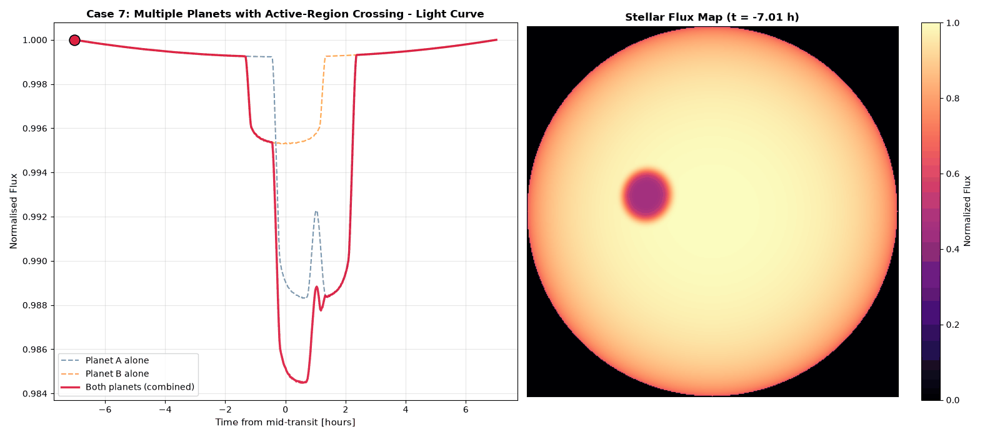

In [12]:
# ------------------------------------------------------------------
# Two planets, transiting together, with different sizes and impact
# parameters -- demonstrates the multi-planet trailing-axis convention:
# every transit-geometry parameter becomes a length-nplanet array
# instead of a scalar. An active region sits along Planet A's chord
# (central transit, b~0) but off Planet B's (offset chord), so only
# Planet A shows a spot-crossing anomaly -- tune AR_LAT/AR_SIZE below
# to taste.
# ------------------------------------------------------------------
RSTAR        = 1.0
P_ROT        = 5.0
STELLAR_GRID = 200

# Planet A: larger, central transit. Planet B: smaller, off-centre chord.
T0           = jnp.array([0.04, 0.0])                        # simultaneous transits
PERIOD       = jnp.array([4.0, 9.0])
A_OVER_RSTAR = jnp.array([12.0, 25.0])
INCLINATION  = jnp.array([90.0, 89.0]) * jnp.pi / 180.0      # A: central; B: off-centre chord
K            = jnp.array([0.1, 0.06])                       # Rp/R*
ECC          = jnp.array([0.0, 0.0])
OMEGA_PERI   = jnp.array([0.0, 0.0])

# Active region positioned along Planet A's chord (same values as
# Case 5/6's spot) -- Planet B's larger impact parameter keeps its chord
# clear of it.
AR_LAT        = 5.0
AR_LONG       = 0.0
AR_SIZE       = 8.0
AR_SMOOTHNESS = 3.0

# Transit duration per planet (used only to size the time window)
b = (A_OVER_RSTAR * jnp.cos(INCLINATION)) / RSTAR * (1 - ECC**2) / (1 + ECC * jnp.sin(OMEGA_PERI))
arg = (1 / A_OVER_RSTAR) * jnp.sqrt((1 + K)**2 - b**2) / jnp.sin(INCLINATION)
arg = np.clip(arg, -1.0, 1.0)
T_dur = (PERIOD / jnp.pi) * jnp.sqrt(1 - ECC**2) / (1 + ECC * jnp.sin(OMEGA_PERI)) * jnp.arcsin(arg)
times = jnp.linspace(-2.5 * jnp.max(T_dur), 2.5 * jnp.max(T_dur), 600)

# ------------------------------------------------------------------
# Scenario 1: Planet A alone (crosses the active region)
# ------------------------------------------------------------------
result_A = quick_lc(
    wavelength        = wave_to_use,
    flux_quiet        = flux_quiet,
    flux_active       = flux_active,
    ld_coeffs         = [u1, u2],
    inc_star          = 90.0,
    ar_lat            = AR_LAT,
    ar_long           = AR_LONG,
    ar_size           = AR_SIZE,
    ar_smoothness     = AR_SMOOTHNESS,
    times             = times,
    P_rot             = P_ROT,
    t0                = T0[0],
    period            = PERIOD[0],
    a_over_rstar      = A_OVER_RSTAR[0],
    inclination       = INCLINATION[0],
    k                 = K[0],
    ecc               = ECC[0],
    omega_peri        = OMEGA_PERI[0],
    stellar_grid_size = STELLAR_GRID,
    ve                = 2.0,
    ld_mode           = "quadratic",
)

# ------------------------------------------------------------------
# Scenario 2: Planet B alone (its chord misses the active region)
# ------------------------------------------------------------------
result_B = quick_lc(
    wavelength        = wave_to_use,
    flux_quiet        = flux_quiet,
    flux_active       = flux_active,
    ld_coeffs         = [u1, u2],
    inc_star          = 90.0,
    ar_lat            = AR_LAT,
    ar_long           = AR_LONG,
    ar_size           = AR_SIZE,
    ar_smoothness     = AR_SMOOTHNESS,
    times             = times,
    P_rot             = P_ROT,
    t0                = T0[1],
    period            = PERIOD[1],
    a_over_rstar      = A_OVER_RSTAR[1],
    inclination       = INCLINATION[1],
    k                 = K[1],
    ecc               = ECC[1],
    omega_peri        = OMEGA_PERI[1],
    stellar_grid_size = STELLAR_GRID,
    ve                = 2.0,
    ld_mode           = "quadratic",
)

# ------------------------------------------------------------------
# Scenario 3: Both planets together -- every transit-geometry keyword
# now takes the length-2 arrays directly, instead of one quick_lc call
# per planet.
# ------------------------------------------------------------------
result_both = quick_lc(
    wavelength        = wave_to_use,
    flux_quiet        = flux_quiet,
    flux_active       = flux_active,
    ld_coeffs         = [u1, u2],
    inc_star          = 90.0,
    ar_lat            = AR_LAT,
    ar_long           = AR_LONG,
    ar_size           = AR_SIZE,
    ar_smoothness     = AR_SMOOTHNESS,
    times             = times,
    P_rot             = P_ROT,
    t0                = T0,
    period            = PERIOD,
    a_over_rstar      = A_OVER_RSTAR,
    inclination       = INCLINATION,
    k                 = K,
    ecc               = ECC,
    omega_peri        = OMEGA_PERI,
    stellar_grid_size = STELLAR_GRID,
    ve                = 2.0,
    ld_mode           = "quadratic",
)

lc_A    = jnp.asarray(result_A[0] / jnp.max(result_A[0]))
lc_B    = jnp.asarray(result_B[0] / jnp.max(result_B[0]))
lc_both = jnp.asarray(result_both[0] / jnp.max(result_both[0]))

star_maps_both = jnp.asarray(result_both[1] / jnp.max(result_both[1]))
vmin7, vmax7   = float(star_maps_both.min()), float(star_maps_both.max())

# Subsample the animation frames -- times has 600 points; this keeps the GIF a manageable size.
frame_idx = jnp.arange(0, len(times), 4)

# ------------------------------------------------------------------
# Plotting: left = light curve with all three scenarios (marker tracking
# the current time on the combined curve); right = both planets crossing
# the stellar disc together, same layout as Case 5/6.
# ------------------------------------------------------------------
fig, (ax_lc, ax_map) = plt.subplots(1, 2, figsize=(16, 7))

ax_lc.plot(times * 24, lc_A,    '--', linewidth=1.5, color='steelblue', alpha=0.8, label='Planet A alone')
ax_lc.plot(times * 24, lc_B,    '--', linewidth=1.5, color='darkorange', alpha=0.8, label='Planet B alone')
ax_lc.plot(times * 24, lc_both, '-',  linewidth=2.5, color='crimson', alpha=0.9, label='Both planets (combined)')
marker7, = ax_lc.plot([times[0] * 24], [lc_both[0]], 'o', markersize=12, color='crimson',
                      markeredgecolor='black', markeredgewidth=1.2, zorder=5)
ax_lc.set_xlabel('Time from mid-transit [hours]', fontsize=11)
ax_lc.set_ylabel('Normalised Flux', fontsize=11)
ax_lc.set_title('Case 7: Multiple Planets with Active-Region Crossing - Light Curve', fontsize=12, fontweight='bold')
ax_lc.legend(fontsize=10)
ax_lc.grid(True, alpha=0.3)

im7 = ax_map.imshow(star_maps_both[frame_idx[0]], cmap='magma', origin='lower', vmin=vmin7, vmax=vmax7)
map_title7 = ax_map.set_title(f'Stellar Flux Map (t = {times[frame_idx[0]] * 24:+.2f} h)',
                               fontsize=12, fontweight='bold')
ax_map.set_xticks([]); ax_map.set_yticks([])
plt.colorbar(im7, ax=ax_map, label='Normalized Flux')
plt.tight_layout()

def _update_case7(i):
    frame = frame_idx[i]
    marker7.set_data([times[frame] * 24], [lc_both[frame]])
    im7.set_data(star_maps_both[frame])
    map_title7.set_text(f'Stellar Flux Map (t = {times[frame] * 24:+.2f} h)')
    return marker7, im7, map_title7

anim7 = FuncAnimation(fig, _update_case7, frames=len(frame_idx), interval=60, blit=False)
with tempfile.NamedTemporaryFile(suffix='.gif', delete=False) as _tmp:
    gif_path = _tmp.name
anim7.save(gif_path, writer=PillowWriter(fps=15))
plt.close(fig)
with open(gif_path, 'rb') as f:
    gif_bytes = f.read()
os.remove(gif_path)
display(Image(data=gif_bytes, format='gif'))

## Case 8 - Dynamic Active-Regions

`flux_active`/`ar_lat`/`ar_long`/`ar_size`/`ar_smoothness` may each independently carry an extra leading time axis (length = the number of `times` the model was built with) instead of their usual per-AR shape, to let that property evolve over the observations. This case demonstrates some relevant setups — a spot growing/decaying, drifting in latitude/longitude, or changing contrast.

Note: the model does not couple active-region properties across epochs — each `times` entry is evaluated independently, with no smoothness/continuity enforced between one entry and the next. If you're doing inference on a dynamic active region, use priors on the epoch-to-epoch changes (e.g. a maximum physically plausible drift/growth rate) to keep it from jumping unrealistically between epochs.

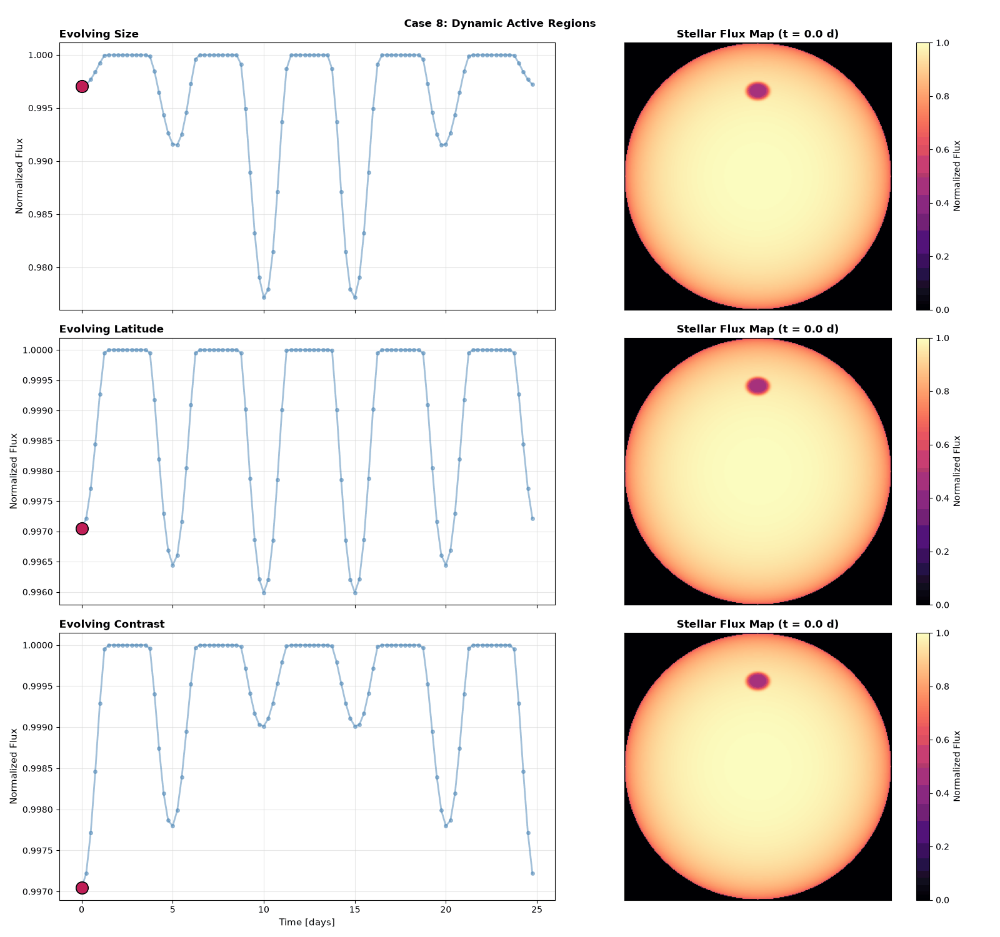

In [13]:
# ------------------------------------------------------------------
# A single spot that grows, drifts toward the equator, or darkens
# over several stellar rotations
# ------------------------------------------------------------------
P_ROT = 5.0                                                  # stellar rotation period [days]
ntime = 100
n_rotations = 5
total_duration = n_rotations * P_ROT
times = jnp.linspace(0, total_duration, ntime, endpoint=False)    # 5 rotations

#Base static properties
wave_to_use = 15_000 #Angstrom
idx_to_use = jnp.abs(wave_to_use - wavelength).argmin()
STATIC_CONTRAST_ACTIVE = spec_active[idx_to_use] / spec_quiet[idx_to_use]
STATIC_AR_LAT        = 40.0        
STATIC_AR_LONG       = 0.0           
STATIC_AR_SIZE       = 5.0           
STATIC_AR_SMOOTHNESS = 3.0          
# Evolving properties, periodic -- shape (ntime, nar=1)
ar_size_evolving      = (
    STATIC_AR_SIZE
    + 5.0 * (1 - jnp.cos(2 * jnp.pi * times / total_duration))  # oscillates between STATIC_AR_SIZE and STATIC_AR_SIZE+10
)[:, None]
ar_lat_evolving       = (
    (STATIC_AR_LAT / 2.0) * (1 + jnp.cos(2 * jnp.pi * times / total_duration))  # oscillates between 0 and STATIC_AR_LAT
)[:, None]
flux_active_evolving  = (
    STATIC_CONTRAST_ACTIVE
    + 0.2 * (1 - jnp.cos(2 * jnp.pi * times / total_duration))  # oscillates between STATIC_CONTRAST_ACTIVE and +0.4
)[:, None, None]

# ------------------------------------------------------------------
# Same layout as Case 1: light curve (marker tracking the current
# time) alongside the evolving stellar flux map -- one row per
# evolving property, all three rows animated on the same time axis.
# ------------------------------------------------------------------
fig, axes = plt.subplots(3, 2, figsize=(16, 15), sharex='col')

row_titles = ['Evolving Size', 'Evolving Latitude', 'Evolving Contrast']
markers, ims, map_titles, lc_list, maps_list = [], [], [], [], []

for evolv_idx, (evolving_prop, prop_time_series) in enumerate(zip(['ar_size', 'ar_lat', 'flux_active'], [ar_size_evolving, ar_lat_evolving, flux_active_evolving])):

    #Building LC and surface map for this row's evolving property
    result_case8 = quick_lc(
        # Static
        wavelength          = wave_to_use,
        flux_quiet          = 1.0,
        ld_coeffs           = [u1, u2],
        inc_star            = 90.0,        
        ar_long             = STATIC_AR_LONG,
        ar_smoothness       = STATIC_AR_SMOOTHNESS,
        times               = times,
        P_rot               = P_ROT,
        stellar_grid_size   = 150,
        ve                  = 2.0,
        ld_mode             = "quadratic",
        #Dynamic -- only this row's property carries the (ntime, nar) time axis
        flux_active         = prop_time_series if evolving_prop=='flux_active' else STATIC_CONTRAST_ACTIVE,
        ar_lat              = prop_time_series if evolving_prop=='ar_lat' else STATIC_AR_LAT,
        ar_size             = prop_time_series if evolving_prop=='ar_size' else STATIC_AR_SIZE,
    )

    lc_case8         = jnp.asarray(result_case8[0])/jnp.max(result_case8[0])
    star_maps_case8  = jnp.asarray(result_case8[1])/jnp.max(result_case8[1])
    vmin8, vmax8     = float(star_maps_case8.min()), float(star_maps_case8.max())
    lc_list.append(lc_case8)
    maps_list.append(star_maps_case8)

    ax_lc, ax_map = axes[evolv_idx, 0], axes[evolv_idx, 1]

    ax_lc.plot(times, lc_case8, 'o-', linewidth=2, markersize=4,
            color='steelblue', alpha=0.5)
    marker8, = ax_lc.plot([times[0]], [lc_case8[0]], 'o', markersize=14,
                        color='crimson', markeredgecolor='black',
                        markeredgewidth=1.2, zorder=5)
    ax_lc.set_ylabel('Normalized Flux', fontsize=11)
    ax_lc.set_title(row_titles[evolv_idx], fontsize=12, fontweight='bold', loc='left')
    ax_lc.grid(True, alpha=0.3)
    markers.append(marker8)

    im8 = ax_map.imshow(star_maps_case8[0], cmap='magma', origin='lower', vmin=vmin8, vmax=vmax8)
    map_title8 = ax_map.set_title(f'Stellar Flux Map (t = {times[0]:.1f} d)',
                                   fontsize=12, fontweight='bold')
    ax_map.set_xticks([]); ax_map.set_yticks([])
    plt.colorbar(im8, ax=ax_map, label='Normalized Flux')
    ims.append(im8)
    map_titles.append(map_title6)

axes[-1, 0].set_xlabel('Time [days]', fontsize=11)
fig.suptitle('Case 8: Dynamic Active Regions', fontsize=12, fontweight='bold')
plt.tight_layout()

# Defined once, after the loop -- updates all three rows every frame via
# the marker/im/title lists built above. (Defining this inside the loop,
# as before, meant only the *last* row's animation ever got wired up:
# every earlier definition of _update_case7 was simply overwritten.)
def _update_case8(frame):
    artists = []
    for i in range(3):
        markers[i].set_data([times[frame]], [lc_list[i][frame]])
        ims[i].set_data(maps_list[i][frame])
        map_titles[i].set_text(f'Stellar Flux Map (t = {times[frame]:.1f} d)')
        artists += [markers[i], ims[i], map_titles[i]]
    return artists

anim8 = FuncAnimation(fig, _update_case8, frames=len(times), interval=80, blit=False)
with tempfile.NamedTemporaryFile(suffix='.gif', delete=False) as _tmp:
    gif_path = _tmp.name
anim8.save(gif_path, writer=PillowWriter(fps=9))
plt.close(fig)
with open(gif_path, 'rb') as f:
    gif_bytes = f.read()
os.remove(gif_path)

display(Image(data=gif_bytes, format='gif'))

## Case 9 - Flares

A stellar flare can be modeled with the dynamic active-region machinery from Case 8: the flare is an active region whose *spectrum* varies in time. Two ingredients are specified independently of the stellar spectrum:

1. **A flare spectrum** -- here a hot blackbody (9,000 K), but any spectrum sampled on the model's `wavelength` grid works.
2. **A time template** -- users can create their own, or use the one provided as `sajax.flare_template`: the [Llamaradas Estelares](https://github.com/lupitatovar/Llamaradas-Estelares) continuous flare model of [Tovar Mendoza et al. (2022)](https://ui.adsabs.harvard.edu/abs/2022AJ....164...17T/abstract), the convolution of a Gaussian with a double exponential, parameterized by a peak time and FWHM.

The flaring region's surface spectrum at each time is `flux_quiet + template(t) * flux_flare`, so its contrast relative to the photosphere rises and decays following the template, and outside the flare the contrast is exactly 1 (the region vanishes). Flare emission is optically-thin-ish chromospheric emission rather than photospheric, so we recommend turning off limb darkening for this region -- here done by passing zero coefficients via `ld_coeffs_active`, while the spot in the same call keeps the photospheric coefficients, demonstrating per-region limb-darkening control. (This, like the template choice, is a suggestion rather than a requirement -- keep limb darkening on if it suits your use case.)

The scenario is Case 5's transit + active-region crossing with the flare added: the same spot and transit geometry, on a time array centered on mid-transit, with the flare peaking ~2.4 hours before the transit so its decay tail is still visible at ingress. As in Case 5, the light-curve panel compares the transit-only and activity-only scenarios against the combined one, here at the wavelength where the flare is strongest. On top sits Case 4's wavelength-resolved 2D light curve of the combined scenario: the flare is an order of magnitude stronger at the blue end of the grid than at the red end (the hot blackbody is much bluer than the cool photosphere), while the transit depth is nearly achromatic by comparison. Because the flare lives on the rotating stellar surface, it is still geometrically foreshortened toward the limb, carried around by rotation, and would be occulted had the planet's chord crossed it.

Peak flare amplitude (flux relative to first sample - 1):
     6000 A :    8.8%
    11949 A :    0.8%
    24040 A :    0.3%


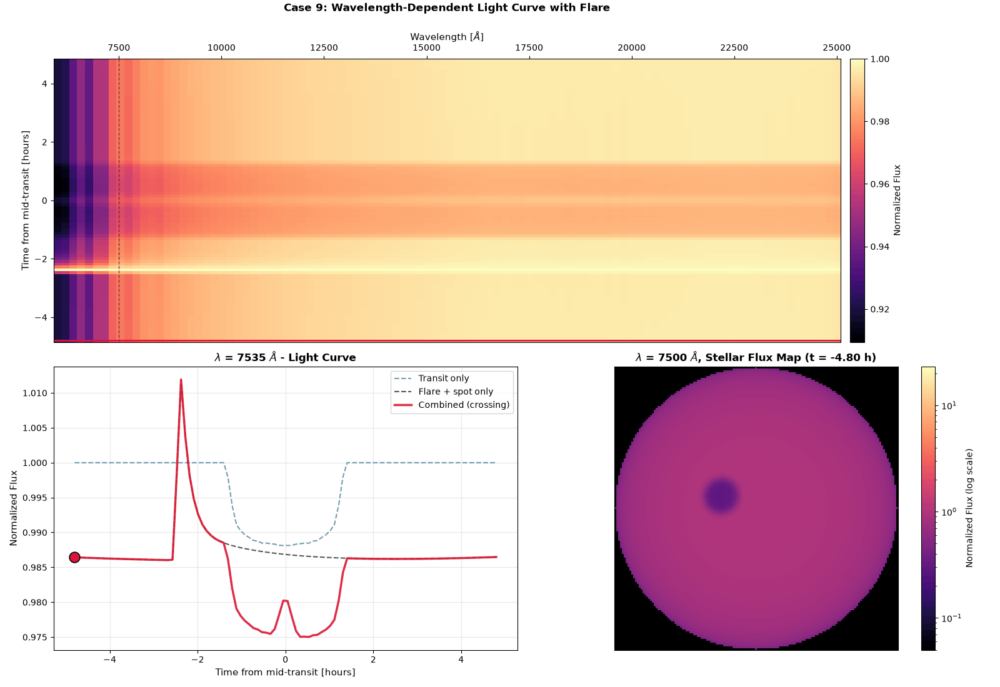

In [14]:
# ------------------------------------------------------------------
# Case 5's transit + active-region crossing, plus a flare: the flare
# spectrum (a hot blackbody) is specified independently of the stellar
# spectrum, and the flaring region's contrast follows the Llamaradas
# Estelares template of Tovar Mendoza et al. (2022).
# ------------------------------------------------------------------
from astropy import constants as const
from matplotlib.colors import LogNorm

from sajax import flare_template


def blackbody_surface_flux(wavelength_aa, teff):
    """pi * B_lambda(teff) in erg s^-1 cm^-2 A^-1 -- the same surface-flux
    units as the speclib spectra loaded above."""
    lam = wavelength_aa * 1e-8                     # Angstrom -> cm
    h, c, k_B = const.h.cgs.value, const.c.cgs.value, const.k_B.cgs.value
    B_lam = 2.0 * h * c**2 / lam**5 / jnp.expm1(h * c / (lam * k_B * teff))
    return jnp.pi * B_lam * 1e-8                   # per cm -> per Angstrom


# ------------------------------------------------------------------
# Same star, spot, and transit geometry as Case 5, on a time array
# centered on mid-transit; the flare peaks ~2.4 hours before the
# transit, so its decay tail is still visible at ingress
# ------------------------------------------------------------------
P_ROT        = 5.0
T0           = 0.0
PERIOD       = 5.0
A_OVER_RSTAR = 15.0
INCLINATION  = jnp.pi / 2.0    # perfectly edge-on
K            = 0.1             # Rp/R* = 0.1

SPOT_LAT, SPOT_LONG   = 5.0, 0.0
SPOT_SIZE, SPOT_SMOOTH = 8.0, 3.0

FLARE_TPEAK = -0.1                                 # [days] before mid-transit
FLARE_FWHM  = 0.01                                 # [days] ~ 14 minutes
T_FLARE     = 9_000.0                              # flare blackbody temperature [K]
FLARE_LAT, FLARE_LONG = 25.0, 0.0                  # off the transit chord
FLARE_SIZE, FLARE_SMOOTH = 2.0, 5.0

times_flare = jnp.linspace(-0.2, 0.2, 100)         # [days] ~ +/-1.7x transit duration

# The flaring region's surface spectrum at each time: quiet photosphere
# plus the template-scaled flare spectrum. With two active regions,
# flux_active is (ntime, nar=2, nwave) -- the spot's column is just its
# static spectrum repeated, the flare's column follows the template.
# Outside the flare its contrast is exactly 1, so that region vanishes.
template   = flare_template(times_flare, FLARE_TPEAK, FLARE_FWHM)      # (ntime,)
flux_flare = blackbody_surface_flux(wavelength, T_FLARE)               # (nwave,)
flux_spot_t  = jnp.broadcast_to(spec_active, (times_flare.size, wavelength.size))
flux_flare_t = spec_quiet[None, :] + template[:, None] * flux_flare[None, :]
flux_active_case9 = jnp.stack([flux_spot_t, flux_flare_t], axis=1)     # (ntime, 2, nwave)

# Per-AR limb darkening: the spot keeps the photospheric coefficients,
# the flare gets zeros -> NOT limb-darkened
ld_coeffs_case9 = jnp.stack([
    jnp.stack([u1_wavelength, u2_wavelength], axis=-1),    # spot   (nwave, 2)
    jnp.zeros((wavelength.size, 2)),                       # flare  (nwave, 2)
])                                                         # (nar, nwave, 2)

# ------------------------------------------------------------------
# Combined scenario, full wavelength grid -- feeds the Case 4-style
# 2D light curve, the per-wavelength light curves, and the flux map
# ------------------------------------------------------------------
result_case9 = quick_lc(
    wavelength          = wavelength,
    flux_quiet          = spec_quiet,
    flux_active         = flux_active_case9,       # (ntime, 2, nwave) -> dynamic
    ld_coeffs           = [u1_wavelength, u2_wavelength],
    ld_coeffs_active    = ld_coeffs_case9,
    inc_star            = 90.0,
    ar_lat              = [SPOT_LAT, FLARE_LAT],
    ar_long             = [SPOT_LONG, FLARE_LONG],
    ar_size             = [SPOT_SIZE, FLARE_SIZE],
    ar_smoothness       = [SPOT_SMOOTH, FLARE_SMOOTH],
    times               = times_flare,
    P_rot               = P_ROT,
    stellar_grid_size   = 75,
    ve                  = 2.0,
    ld_mode             = "quadratic",
    t0                  = T0,
    period              = PERIOD,
    a_over_rstar        = A_OVER_RSTAR,
    inclination         = INCLINATION,
    k                   = K,
    plot_map_wavelength = 7_500.0,                 # map the blue end, where the flare is strongest
)

lc_case9        = jnp.asarray(result_case9[0])     # (ntime, nwave)
star_maps_case9 = jnp.asarray(result_case9[1])

# ------------------------------------------------------------------
# Case 5's two reference scenarios, evaluated only at the wavelength
# where the flare is strongest (the blue end of the grid)
# ------------------------------------------------------------------
wave_ref = 7_500.0
iw_ref   = int(jnp.abs(wave_ref - wavelength).argmin())
TINY     = 0.0001   # effectively "no AR" (negligible angular size), as in Cases 3 and 5

# Scenario 1: transit only -- quiet star, no spot, no flare
result_transit_only9 = quick_lc(
    wavelength          = wavelength[iw_ref],
    flux_quiet          = spec_quiet[iw_ref],
    flux_active         = spec_quiet[iw_ref],
    ld_coeffs           = [u1_wavelength[iw_ref], u2_wavelength[iw_ref]],
    inc_star            = 90.0,
    ar_lat              = SPOT_LAT,
    ar_long             = SPOT_LONG,
    ar_size             = TINY,
    ar_smoothness       = SPOT_SMOOTH,
    times               = times_flare,
    P_rot               = P_ROT,
    stellar_grid_size   = 75,
    ve                  = 2.0,
    ld_mode             = "quadratic",
    t0                  = T0,
    period              = PERIOD,
    a_over_rstar        = A_OVER_RSTAR,
    inclination         = INCLINATION,
    k                   = K,
)

# Scenario 2: activity only -- spot and flare visible, no transit
result_activity_only9 = quick_lc(
    wavelength          = wavelength[iw_ref],
    flux_quiet          = spec_quiet[iw_ref],
    flux_active         = flux_active_case9[:, :, iw_ref:iw_ref + 1],
    ld_coeffs           = [u1_wavelength[iw_ref], u2_wavelength[iw_ref]],
    ld_coeffs_active    = ld_coeffs_case9[:, iw_ref:iw_ref + 1, :],
    inc_star            = 90.0,
    ar_lat              = [SPOT_LAT, FLARE_LAT],
    ar_long             = [SPOT_LONG, FLARE_LONG],
    ar_size             = [SPOT_SIZE, FLARE_SIZE],
    ar_smoothness       = [SPOT_SMOOTH, FLARE_SMOOTH],
    times               = times_flare,
    P_rot               = P_ROT,
    stellar_grid_size   = 75,
    ve                  = 2.0,
    ld_mode             = "quadratic",
)

# Scenario 3 (combined) is the chromatic run above, sliced at wave_ref.
# All three normalized by the transit-only maximum, as in Case 5.
norm_ref     = jnp.max(result_transit_only9[0])
lc_transit9  = jnp.asarray(result_transit_only9[0] / norm_ref)
lc_activity9 = jnp.asarray(result_activity_only9[0] / norm_ref)
lc_combined9 = jnp.asarray(lc_case9[:, iw_ref] / norm_ref)

# Case 4-style 2D map: each wavelength's own light curve normalized to
# its own maximum (the flare peak, here)
flux_wl_map9 = lc_case9 / jnp.max(lc_case9, axis=0)

print("Peak flare amplitude (flux relative to first sample - 1):")
for pw in [6_000.0, 12_000.0, 24_000.0]:
    iw = int(jnp.abs(pw - wavelength).argmin())
    print(f"  {wavelength[iw]:7.0f} A : {jnp.max(lc_case9[:, iw]) / lc_case9[0, iw] - 1.0:7.1%}")

# ------------------------------------------------------------------
# Top (spans both columns): wavelength-resolved 2D light curve, as in
# Case 4, with a horizontal line tracking the animation's current time.
# Bottom row (animated): the Case 5 scenario comparison at 6000 A and
# the stellar flux map -- the flare erupts, then the planet transits
# and crosses the spot.
# ------------------------------------------------------------------
fig, axes = plt.subplot_mosaic([['A', 'A'], ['C', 'D']], figsize=(16, 11))

ax = axes['A']
im_top = ax.pcolormesh(wavelength, times_flare * 24, flux_wl_map9,
                       shading='auto', cmap='magma')
ax.axvline(wave_ref, color='k', linestyle='--', linewidth=1, alpha=0.6)
time_line9 = ax.axhline(times_flare[0] * 24, color='crimson', linewidth=2)
ax.set_xlabel('Wavelength [$\AA$]', fontsize=11)
ax.set_ylabel('Time from mid-transit [hours]', fontsize=11)
ax.set_title('Case 9: Wavelength-Dependent Light Curve with Flare', fontsize=12, fontweight='bold', y=1.15)
ax.xaxis.set_label_position('top')
ax.xaxis.set_ticks_position('top')
plt.colorbar(im_top, ax=ax, label='Normalized Flux', pad=0.01)

ax_lc = axes['C']
ax_lc.plot(times_flare * 24, lc_transit9,  '--', linewidth=1.5, color='steelblue', alpha=0.8, label='Transit only')
ax_lc.plot(times_flare * 24, lc_activity9, '--', linewidth=1.5, color='green',     alpha=0.8, label='Flare + spot only')
ax_lc.plot(times_flare * 24, lc_combined9, '-',  linewidth=2.5, color='crimson',   alpha=0.9, label='Combined (crossing)')
marker9, = ax_lc.plot([times_flare[0] * 24], [lc_combined9[0]], 'o', markersize=12, color='crimson',
                      markeredgecolor='black', markeredgewidth=1.2, zorder=5)
ax_lc.set_xlabel('Time from mid-transit [hours]', fontsize=11)
ax_lc.set_ylabel('Normalized Flux', fontsize=11)
ax_lc.set_title('$\\lambda$' + f' = {wavelength[iw_ref]:.0f}' + ' $\\AA$' + ' - Light Curve',
                fontsize=12, fontweight='bold')
ax_lc.legend(fontsize=10)
ax_lc.grid(True, alpha=0.3)

ax_map = axes['D']
# Log color scale: the flare outshines the photosphere by more than an
# order of magnitude at this wavelength, so a linear scale would black
# out the stellar disc entirely. Zero-flux pixels (the planet's
# silhouette and the sky around the disc) are masked by the log norm;
# paint them black.
cmap_map9 = plt.get_cmap('magma').copy()
cmap_map9.set_bad('black')
maps_rel = star_maps_case9 / star_maps_case9[0].max()
im9 = ax_map.imshow(maps_rel[0], cmap=cmap_map9, origin='lower',
                    norm=LogNorm(vmin=0.05, vmax=float(maps_rel.max())))
ax_map.set_xticks([]); ax_map.set_yticks([])
map_title9 = ax_map.set_title(
    '$\\lambda$' + ' = 7500 ' + '$\\AA$' + f', Stellar Flux Map (t = {times_flare[0] * 24:+.2f} h)',
    fontsize=12, fontweight='bold')
plt.colorbar(im9, ax=ax_map, label='Normalized Flux (log scale)')

plt.tight_layout()


def _update_case9(frame):
    t_h = float(times_flare[frame]) * 24
    time_line9.set_ydata([t_h, t_h])
    marker9.set_data([t_h], [lc_combined9[frame]])
    im9.set_data(maps_rel[frame])
    map_title9.set_text(
        '$\\lambda$' + ' = 7500 ' + '$\\AA$' + f', Stellar Flux Map (t = {t_h:+.2f} h)')
    return marker9, time_line9, im9, map_title9


anim9 = FuncAnimation(fig, _update_case9, frames=len(times_flare), interval=80, blit=False)
with tempfile.NamedTemporaryFile(suffix='.gif', delete=False) as _tmp:
    gif_path = _tmp.name
anim9.save(gif_path, writer=PillowWriter(fps=9))
plt.close(fig)
with open(gif_path, 'rb') as f:
    gif_bytes = f.read()
os.remove(gif_path)
display(Image(data=gif_bytes, format='gif'))

## The Super-Gaussian Shape of Active Regions

SAJAX models every active region as a **super-Gaussian** bump on the stellar surface rather than a hard-edged spot. Each active region has two shape parameters:

- `ar_size` — the angular radius (its "standard deviation"), and
- `ar_smoothness` or `n` — the super-Gaussian order, which controls how sharply the region's edge falls off:
  - `n = 1` is a **Gaussian** falloff,
  - larger values sharpen the boundary, converging toward a **hard-edged (top-hat) spot** as `n -> infinity`.

Overlapping active regions combine additively — so a small, sharp umbra sitting inside a broad, soft penumbra is naturally supported.

The cell below computes the stellar flux map for the same active region at a few different `n` values, so you can see the Gaussian to top-hat transition directly.

You may notice that the order in which the curves fall is a little counter-intuitive: because every curve shares the same `arsize_rad`, the AR's total flux impact isn't monotonic as a function of `ar_smoothness` — it dips to a minimum around n≈2-3 (the shrinking Gaussian tail outpaces the flattening core) before rising back toward the top-hat limit. That's why n=1 and n=50 can produce similar light-curve depths while n=2/n=5 sit shallower in between.

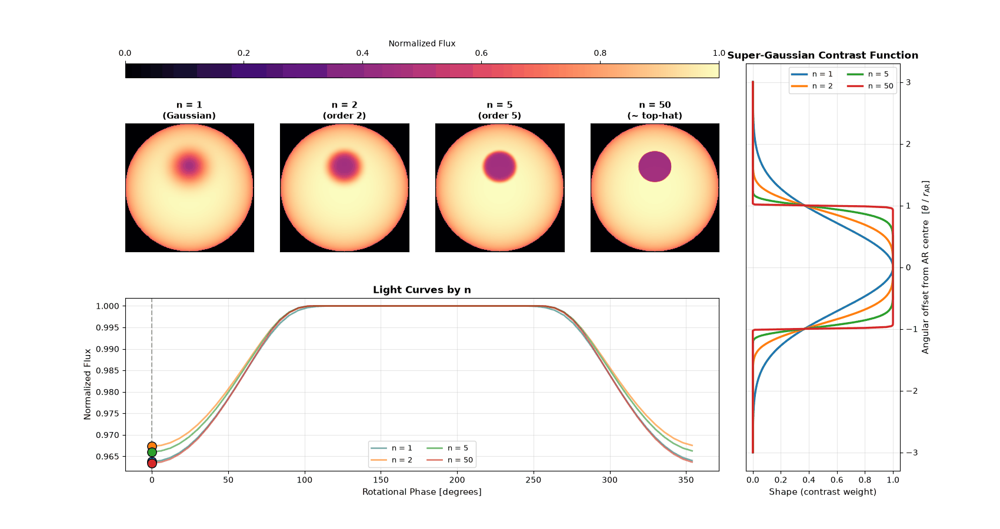

In [15]:
smoothness_values = [1.0, 2.0, 5.0, 50.0]
AR_SIZE_DEG = 15.0

# We define an array of time values from rotation phases we want to parse
P_ROT  = 5.0                                     # stellar rotation period [days]
phases = jnp.linspace(0, 360, 60, endpoint=False)
times  = phases / 360.0 * P_ROT

#Iterate over the smoothness values and compute the light curves and maps for each value
maps_by_smoothness = []
lcs_by_smoothness   = []
for n in smoothness_values:
    result_n = quick_lc(
        wavelength          = wave_to_use,
        flux_quiet          = flux_quiet,
        flux_active         = flux_active,
        ld_coeffs           = [u1, u2],                  
        inc_star            = 90.0,                      
        ar_lat              = 20.0,
        ar_long             = 0.0,
        ar_size             = AR_SIZE_DEG,
        ar_smoothness       = n,
        times               = times,
        P_rot               = P_ROT,
        stellar_grid_size   = 100,
        ve                  = 2.0,
        ld_mode             = "quadratic",
    )
    maps_by_smoothness.append(jnp.asarray(result_n[1]/jnp.max(result_n[1])))     # (ntimes, n_cells, n_cells)
    lcs_by_smoothness.append(jnp.asarray(result_n[0]/jnp.max(result_n[0])))      # (ntimes,) -- single-wavelength call

# Shared flux color scale across all four columns and every frame
all_maps   = jnp.stack(maps_by_smoothness)
vmin, vmax = float(all_maps.min()), float(all_maps.max())

# ---------------------------------------------------------------------
# Figure: top row = each smoothness value's rotating stellar flux map
# bottom row = a single shared plot with all four light curves overlaid
# ---------------------------------------------------------------------
fig, axes = plt.subplot_mosaic(
    [['cbar', 'cbar', 'cbar', 'cbar', 'F'],
     ['A', 'B', 'C', 'D', 'F'],
     ['E', 'E', 'E', 'E', 'F']],
    figsize=(17, 9), height_ratios=[0.08, 1, 1],
    width_ratios=[1, 1, 1, 1, 1.2])

colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

map_axes, map_ims = [], []
for i, (n, ax) in enumerate(zip(smoothness_values, [axes['A'], axes['B'], axes['C'], axes['D']])):
    label = "Gaussian" if n == 1.0 else ("~ top-hat" if n >= 50 else f"order {n:g}")
    im = ax.imshow(maps_by_smoothness[i][0], cmap='magma', origin='lower',
                        vmin=vmin, vmax=vmax)
    ax.set_title(f"n = {n:g}\n({label})", fontsize=11, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])
    map_axes.append(ax); map_ims.append(im)

sm = plt.cm.ScalarMappable(cmap='magma', norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm.set_array([])
cbar = fig.colorbar(sm, cax=axes['cbar'], orientation='horizontal',
             label='Normalized Flux')
axes['cbar'].xaxis.set_label_position('top')
axes['cbar'].xaxis.set_ticks_position('top')

markers = []
for i, n in enumerate(smoothness_values):
    axes['E'].plot(phases, lcs_by_smoothness[i], '-', linewidth=2, color=colors[i],
               alpha=0.6, label=f'n = {n:g}')
    marker, = axes['E'].plot([phases[0]], [lcs_by_smoothness[i][0]], 'o', markersize=11,
                         color=colors[i], markeredgecolor='black', markeredgewidth=1.0,
                         zorder=5)
    markers.append(marker)
scan_line = axes['E'].axvline(phases[0], color='grey', linestyle='--', linewidth=1.5, alpha=0.7)
axes['E'].set_xlabel('Rotational Phase [degrees]', fontsize=11)
axes['E'].set_ylabel('Normalized Flux', fontsize=11)
axes['E'].set_title('Light Curves by n', fontsize=12, fontweight='bold')
axes['E'].legend(fontsize=9, loc='lower center', ncols=2)
axes['E'].grid(True, alpha=0.3)

# -------------------------------
# The super-Gaussian shape itself
# -------------------------------
theta0 = jnp.radians(AR_SIZE_DEG)
theta  = jnp.linspace(-3, 3, 400) * theta0

# Calls the real _compute_ar_shape formula directly.
# Points are swept along a great circle through an AR centred at the sub-observer point.
star_pixel_rad_demo = 1.0
x_disc_demo = star_pixel_rad_demo * jnp.sin(theta)
y_disc_demo = jnp.zeros_like(theta)
for i, n in enumerate(smoothness_values):
    shape = _compute_ar_shape(
        x_disc_demo, y_disc_demo, star_pixel_rad_demo,
        0.0, 0.0, star_pixel_rad_demo,   # AR centre (spx, spy, spz)
        theta0, n,
    )
    axes['F'].plot(shape, theta / theta0, '-', linewidth=2.5, color=colors[i],
                    label=f'n = {n:g}')
axes['F'].set_ylabel(r'Angular offset from AR centre  [$\theta$ / $r_{\rm AR}$]', fontsize=11)
axes['F'].yaxis.set_label_position('right')
axes['F'].yaxis.set_ticks_position('right')
axes['F'].set_xlabel('Shape (contrast weight)', fontsize=11)
axes['F'].set_title('Super-Gaussian Contrast Function', fontsize=12, fontweight='bold')
axes['F'].legend(fontsize=9, loc='upper right', ncols=2)
axes['F'].grid(True, alpha=0.3)

def _update(frame):
    artists = []
    for i in range(len(smoothness_values)):
        map_ims[i].set_data(maps_by_smoothness[i][frame])
        markers[i].set_data([phases[frame]], [lcs_by_smoothness[i][frame]])
        artists += [map_ims[i], markers[i]]
    scan_line.set_xdata([phases[frame], phases[frame]])
    artists.append(scan_line)
    return artists

anim = FuncAnimation(fig, _update, frames=len(phases), interval=80, blit=False)

with tempfile.NamedTemporaryFile(suffix='.gif', delete=False) as _tmp:
    gif_path = _tmp.name
anim.save(gif_path, writer=PillowWriter(fps=9))
fig.tight_layout()
plt.close(fig)
with open(gif_path, 'rb') as f:
    gif_bytes = f.read()
os.remove(gif_path)

display(Image(data=gif_bytes, format='gif'))

## Rotational (Doppler) Broadening

Every stellar-surface pixel's spectrum is Doppler-shifted by its corresponding line-of-sight velocity before `SAJAX` samples it at the wavelength. The stellar spin axis is the sky-frame $y$-axis, so that velocity depends only on a pixel's $x$-coordinate: pixels on the $+x$ limb are redshifted, pixels on the $-x$ limb are blueshifted, and the whole $x = 0$ meridian -- including the poles -- has zero rotational velocity, regardless of $y$.

Integrated over the visible disk, this smears a narrow spectral line out into the classic $v\sin i$-rotationally-broadened profile: wider and shallower for faster rotators, at fixed equivalent width. the spectra in this notebook are sampled far too coarsely (100 points across 6000-25000 Å) to resolve a line profile so we build a synthetic Gaussian absorption line instead, and disk-integrate it at a few equatorial velocities `ve`. We give the active region the same spectrum as the quiet photosphere (contrast = 1), so it stays invisible in flux and the only thing varying below is the rotational velocity field -- visible directly in the resolved stellar maps at the line centre, which show flux dipping only along the zero-velocity $x=0$ meridian as `ve` increases.

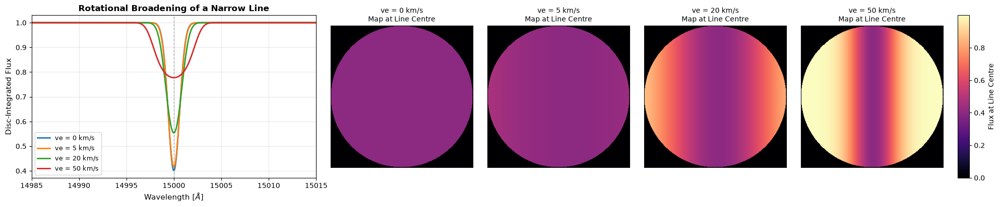

In [16]:
# A narrow synthetic absorption line -- SAJAX's own bundled spectra
# (100 points over 6000-25000 A) are too coarse to resolve one.
line_wl    = jnp.linspace(14_950.0, 15_050.0, 1000)   # narrow window around 15000 A
line_lam0  = 15_000.0
line_sigma = 0.6                                      # intrinsic (non-rotating) line width [A]
line_depth = 0.6
line_spec  = 1.0 - line_depth * jnp.exp(-0.5 * ((line_wl - line_lam0) / line_sigma) ** 2)

times_broadening = jnp.array([0.0])   # a static snapshot
ve_values = [0.0, 5.0, 20.0, 50.0]    # equatorial velocity [km/s]

lc_by_ve, map_by_ve = [], []
for ve_i in ve_values:
    result_ve = quick_lc(
        wavelength          = line_wl,
        flux_quiet          = line_spec,
        flux_active         = line_spec,         # contrast = 1 -> AR is invisible
        ld_coeffs           = [0.0, 0.0],        # no limb darkening -- isolate the Doppler effect
        inc_star            = 90.0,
        ar_lat              = 0.0,
        ar_long             = 0.0,
        ar_size             = 1.0,
        ar_smoothness       = 1.0,
        times               = times_broadening,
        P_rot               = P_ROT,
        stellar_grid_size   = 150,
        ve                  = ve_i,
        ld_mode             = "quadratic",
        plot_map_wavelength = line_lam0,
    )
    lc_by_ve.append(jnp.asarray(result_ve[0])[0])    # (nwave,) disk-integrated line profile
    map_by_ve.append(jnp.asarray(result_ve[1])[0])   # (n, n) stellar map at line centre

all_maps       = jnp.stack(map_by_ve)
vmin_m, vmax_m = float(all_maps.min()), float(all_maps.max())
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

fig, axes = plt.subplots(1, 6, figsize=(24, 4.2), gridspec_kw={'width_ratios':[2, 1, 1, 1, 1, 0.08], 'wspace':0.1})
ax_line  = axes[0]
map_axes = axes[1:5]
cax      = axes[5]

for i, ve_i in enumerate(ve_values):
    ax_line.plot(line_wl, lc_by_ve[i], linewidth=2, color=colors[i], label=f've = {ve_i:g} km/s')
ax_line.axvline(line_lam0, color='grey', linestyle='--', linewidth=1, alpha=0.6)
ax_line.set_xlim(line_lam0 - 15.0, line_lam0 + 15.0)
ax_line.set_xlabel('Wavelength [$\AA$]', fontsize=11)
ax_line.set_ylabel('Disc-Integrated Flux', fontsize=11)
ax_line.set_title('Rotational Broadening of a Narrow Line', fontsize=12, fontweight='bold')
ax_line.legend(fontsize=9)
ax_line.grid(True, alpha=0.3)

im = None
for i, (ve_i, ax) in enumerate(zip(ve_values, map_axes)):
    im = ax.imshow(map_by_ve[i], cmap='magma', origin='lower', vmin=vmin_m, vmax=vmax_m)
    ax.set_title(f've = {ve_i:g} km/s\nMap at Line Centre', fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, cax=cax, label='Flux at Line Centre')
plt.show()